This code is authored by Rohieth Raj S

In [5]:
import pandas as pd
nodes_df = pd.read_csv('nodes_clean_colored.csv')
edges_df = pd.read_csv('edges_clean_2.csv')

correct_nodes = set(edges_df['Source']).union(set(edges_df['Target']))
print(correct_nodes)
cleaned_nodes = nodes_df[nodes_df['Id'].isin(correct_nodes)]

cleaned_nodes.to_csv('cleaned_nodes_2.csv', index=False)

{'D02595', 'D03472', 'D01401', 'achari masala', 'D01200', 'D01496', 'D04114', 'D03977', 'D03775', 'D01987', 'D03621', 'D02031', 'D02828', 'D00144', 'D03633', 'D04156', 'D05143', 'D00149', 'D04569', 'D02347', 'D00399', 'D04922', 'D05040', 'D02803', 'D02635', 'D00750', 'D01559', 'D01049', 'D05746', 'D02456', 'D03139', 'baby corn', 'D03370', 'bajra dosa batter', 'D05852', 'D05385', 'D01240', 'D01331', 'D00151', 'D01827', 'dates', 'D01164', 'D05229', 'D00749', 'D05918', 'D01617', 'D02130', 'D05797', 'D01182', 'D01009', 'D01266', 'D01548', 'D04360', 'D05349', 'tomato salsa', 'pita saga', 'D02778', 'D04224', 'D00400', 'red poha', 'D02051', 'D04504', 'D01423', 'D03766', 'D00907', 'D02691', 'D04891', 'D05428', 'jaggery', 'D00129', 'D02588', 'D05227', 'D02022', 'D05165', 'bimbla', 'D05507', 'lamb ribs', 'D01075', 'D05835', 'D04595', 'D02746', 'D05331', 'D00825', 'D05512', 'D01107', 'D01598', 'D02089', 'D04229', 'mooli/ mullangi', 'lemon zest', 'radish leaves', 'D04827', 'thandai syrup', 'D04061

In [9]:
s = correct_nodes - set(nodes_df["Id"])

print(s)

{'purple carrot', 'batua', 'chocolate ice cream', 'mayonnaise', 'gm arabica leaves', 'fried onion', 'corn dalia', 'gobi leaves', 'rye', 'dry kashmiri pepper', 'roasted chana lentil', 'yogurt', 'salt oil', 'whole wheat khakras', 'fresh jasmine bud', 'nagkesar/cassia bud', 'chickpea chana or chickpeas', 'gm arabica', 'mustard', 'edible camphor', 'farsan', 'crush 1gram flour', 'slivered badam', 'badam meal', 'red yellow and green bell pepper', 'dry red pepper', 'roasted tomato sauce', 'knol khol leaves', 'pickled onion', 'whole cashew', 'chocolate candies', 'green pepper', 'branch green coriander', 'coriander', 'vanilla ice cream', 'pearl onion', 'ghost chilli pepper', 'caramelized onion', 'badam milk', 'white urad lentil', 'sprig coriander leaves', 'raita masala', 'red chili powder'}



Ingredient: mango
                          Ingredient_Dishes  Total_Dishes  Prevalence (%)
Cuisine                                                                  
Malvani                                 1.0             7           14.29
Coorg                                   1.0            14            7.14
Gujarati Recipes﻿                       6.0            96            6.25
Kerala Recipes                          8.0           133            6.02
Andhra                                  6.0           109            5.50
Mangalorean                             2.0            45            4.44
Oriya Recipes                           1.0            26            3.85
Karnataka                               5.0           138            3.62
Maharashtrian Recipes                   5.0           152            3.29
Konkan                                  1.0            32            3.12
Indian                                 26.0           927            2.80
Parsi Recipes      

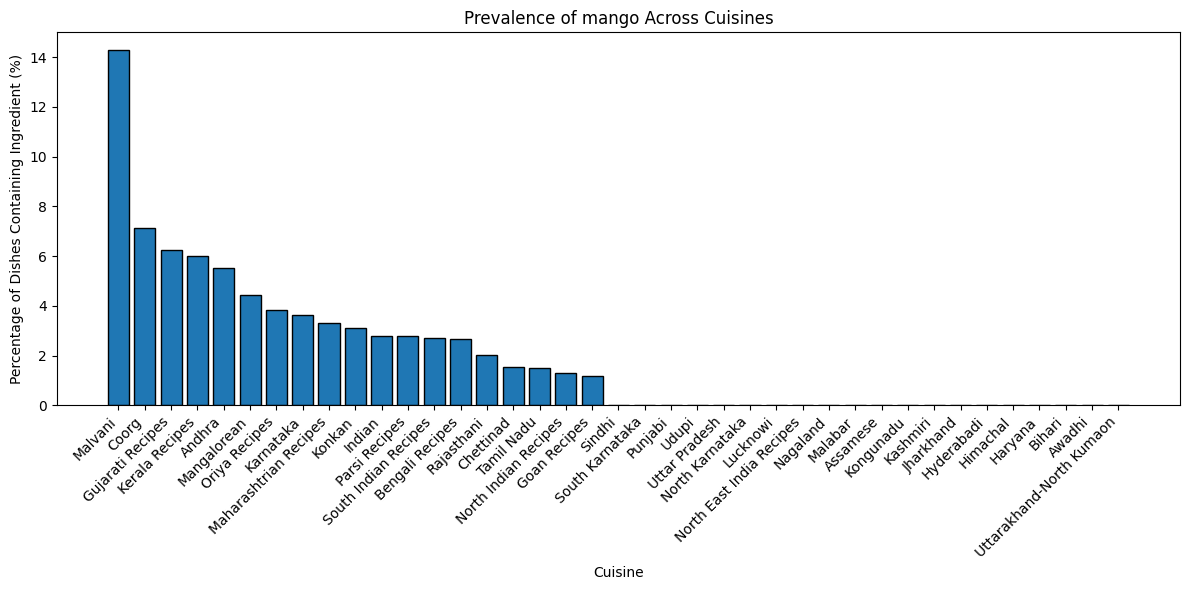

In [9]:

import pandas as pd
import matplotlib.pyplot as plt

# 1. Load datasets
nodes_df = pd.read_csv('cleaned_nodes_2.csv')
edges_df = pd.read_csv('edges_clean_2.csv')

# 2. Separate recipes and ingredients
recipes = nodes_df[nodes_df['Type'] == 'Recipe'].copy()
ingredients = nodes_df[nodes_df['Type'] != 'Recipe'].copy()

# 3. Take ingredient input
ingredient_name = input("Enter ingredient name: ").strip().lower()

matching_ingredients = ingredients[
    (ingredients['Label'].astype(str).str.lower() == ingredient_name) |
    (ingredients['Id'].astype(str).str.lower() == ingredient_name)
]

if matching_ingredients.empty:
    print("Ingredient not found!")

else:
    ingredient_ids = set(matching_ingredients['Id'])

    # 4. Find recipes connected to the ingredient
    connected_recipes = set()

    for source, target in edges_df[['Source', 'Target']].itertuples(
        index=False, name=None
    ):
        if source in ingredient_ids:
            connected_recipes.add(target)
        elif target in ingredient_ids:
            connected_recipes.add(source)

    # Retain only recipe IDs
    connected_recipes &= set(recipes['Id'])

    # 5. Total number of dishes in each cuisine
    total_dishes = recipes.groupby('Cuisine')['Id'].nunique()

    # 6. Number of dishes containing ingredient in each cuisine
    ingredient_dishes = recipes[
        recipes['Id'].isin(connected_recipes)
    ]

    ingredient_counts = ingredient_dishes.groupby('Cuisine')['Id'].nunique()

    # 7. Combine and normalize
    results = pd.DataFrame({
        'Ingredient_Dishes': ingredient_counts,
        'Total_Dishes': total_dishes
    }).fillna(0)

    results['Prevalence (%)'] = (
        results['Ingredient_Dishes'] /
        results['Total_Dishes']
    ) * 100

    results = results.sort_values(
        'Prevalence (%)', ascending=False
    )

    # 8. Display results
    print(f"\nIngredient: {ingredient_name}")
    print(results.round(2).to_string())

    # 9. Plot normalized prevalence
    plt.figure(figsize=(12, 6))

    plt.bar(
        results.index.astype(str),
        results['Prevalence (%)'],
        edgecolor='black'
    )

    plt.title(f'Prevalence of {ingredient_name} Across Cuisines')
    plt.xlabel('Cuisine')
    plt.ylabel('Percentage of Dishes Containing Ingredient (%)')
    plt.xticks(rotation=45, ha='right')
    plt.tight_layout()
    plt.show()


In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# ==========================================
# 1. LOAD & PREPARE BIPARTITE NETWORK DATA
# ==========================================
nodes_df = pd.read_csv('nodes_9.0.csv')
edges_df = pd.read_csv('edges_6.0.csv')

# Clean invisible BOM characters and whitespace in Cuisine names
nodes_df['Cuisine'] = (
    nodes_df['Cuisine']
    .astype(str)
    .str.replace('\ufeff', '', regex=False)
    .str.strip()
)

recipes = nodes_df[nodes_df['Type'] == 'Recipe'].copy()
recipe_cuisine_map = recipes.set_index('Id')['Cuisine'].to_dict()
recipe_label_map = recipes.set_index('Id')['Label'].astype(str).str.lower().to_dict()

# Standardize edge direction: Recipe_Id -> Ingredient
is_source_recipe = edges_df['Source'].isin(recipe_cuisine_map)
e1 = edges_df[is_source_recipe][['Source', 'Target']].rename(
    columns={'Source': 'Recipe_Id', 'Target': 'Ingredient'}
)
e2 = edges_df[~is_source_recipe][['Target', 'Source']].rename(
    columns={'Target': 'Recipe_Id', 'Source': 'Ingredient'}
)
rel_df = pd.concat([e1, e2], ignore_index=True).drop_duplicates()
rel_df['Ingredient'] = rel_df['Ingredient'].astype(str).str.lower().str.strip()
rel_df['Cuisine'] = rel_df['Recipe_Id'].map(recipe_cuisine_map)
rel_df['Recipe_Label'] = rel_df['Recipe_Id'].map(recipe_label_map)

# Filter out generic 'Indian' and cuisines with fewer than MIN_DISHES recipes
MIN_DISHES = 10
cuisine_totals = recipes.groupby('Cuisine')['Id'].nunique()
valid_cuisines = cuisine_totals[
    (cuisine_totals >= MIN_DISHES) & (cuisine_totals.index != 'Indian')
].index.tolist()

rel_df = rel_df[rel_df['Cuisine'].isin(valid_cuisines)].copy()
cuisine_totals = cuisine_totals.loc[valid_cuisines]

# ==========================================
# 2. SMART DISAMBIGUATION FOR 'MILLET FLOUR'
# ==========================================
# Recover specific millet varieties from Recipe Labels when Ingredient == 'millet flour'
expanded_rows = []
for idx, row in rel_df[rel_df['Ingredient'] == 'millet flour'].iterrows():
    lbl = row['Recipe_Label']
    matched = False
    if any(k in lbl for k in ['ragi', 'finger millet', 'nachni', 'kezhvaragu']):
        r = row.copy(); r['Ingredient'] = 'ragi (grain & flour)'; expanded_rows.append(r); matched = True
    if any(k in lbl for k in ['jowar', 'jolada', 'sorghum', 'cholam']):
        r = row.copy(); r['Ingredient'] = 'jowar (grain & flour)'; expanded_rows.append(r); matched = True
    if any(k in lbl for k in ['bajra', 'kambu', 'pearl millet']):
        r = row.copy(); r['Ingredient'] = 'bajra (grain & flour)'; expanded_rows.append(r); matched = True
    if not matched:
        r = row.copy(); r['Ingredient'] = 'multigrain / other millet flour'; expanded_rows.append(r)

# Also map raw 'ragi', 'jowar seeds', 'bajra' into the unified variety names
rel_df['Ingredient'] = rel_df['Ingredient'].replace({
    'ragi': 'ragi (grain & flour)',
    'jowar seeds': 'jowar (grain & flour)',
    'bajra': 'bajra (grain & flour)'
})
rel_df = pd.concat([rel_df[rel_df['Ingredient'] != 'millet flour'], pd.DataFrame(expanded_rows)], ignore_index=True)
rel_df = rel_df.drop_duplicates(subset=['Recipe_Id', 'Ingredient'])

# ==========================================
# 3. DEFINE THE 5 SUB-VARIETY FAMILIES
# ==========================================
ingredient_families = {
    "1. Millets & Pseudo-Cereals": [
        'ragi (grain & flour)', 'bajra (grain & flour)', 'jowar (grain & flour)',
        'foxtail millet', 'barnyard millet', 'kodo millet', 'amaranth seeds',
        'buckwheat flour', 'samvat rice', 'multigrain / other millet flour'
    ],
    "2. Rice Varieties & Flakes": [
        'rice', 'basmati rice', 'poha', 'puffed rice', 'brown rice',
        'matta rice', 'govind bhog rice', 'black rice', 'seeraga samba rice',
        'sona masuri rice', 'jasmine rice'
    ],
    "3. Regional & Specialty Masalas": [
        'garam masala', 'chaat masala powder', 'sambar powder', 'panch phoran masala',
        'maharashtrian goda masala', 'goda masala', 'rasam powder', 'pav bhaji masala',
        'tandoori masala', 'biryani masala', 'achari masala', 'chana masala powder',
        'bisi bele bhat spice powder', 'goan recheado masala', 'reacheado masala',
        'kolhapuri masala', 'malwani masala', 'saoji masala', 'koli masala',
        'bhaja masala', 'vangi bath powder', 'puliodarai powder', 'dhansak masala'
    ],
    "4. Leafy Greens & Culinary Leaves": [
        'coriander leaves', 'curry leaves', 'bay leaves', 'mint', 'methi leaves',
        'spinach', 'spring onion', 'dill leaves', 'drumstick leaves', 'gongura leaves',
        'amaranth leaves', 'green amaranth leaves', 'red amaranth leaves',
        'colocasia leaves', 'bathua leaves', 'banana leaves', 'turmeric leaves',
        'mustard greens', 'agathi keerai', 'radish leaves', 'betel leaves', 'tulsi'
    ],
    "5. Signature Whole & Ground Spices": [
        'red chilli', 'turmeric', 'green chilli', 'cumin', 'mustard seeds',
        'coriander seeds', 'asafoetida', 'cardamom', 'cinnamon', 'tamarind',
        'cloves', 'fennel seeds', 'methi seeds', 'black peppercorns', 'pepper',
        'ajwain', 'amchur', 'saffron', 'kashmiri red chilli', 'kalonji',
        'black cardamom', 'nutmeg', 'kokum', 'star anise', 'mace', 'Mustard',
        'guntur chilli', 'black salt', 'rock salt', 'anardana seeds', 'kachampuli'
    ]
}

# ==========================================
# 4. COMPUTE REGIONAL PREVALENCE & PLOT
# ==========================================
def analyze_and_plot_family(family_name, item_list, top_n_items=12):
    sub_df = rel_df[rel_df['Ingredient'].isin([x.lower() for x in item_list])]
    if sub_df.empty:
        return None
    
    # Keep top N most frequent varieties in this family for visual clarity
    top_varieties = sub_df['Ingredient'].value_counts().head(top_n_items).index.tolist()
    sub_df = sub_df[sub_df['Ingredient'].isin(top_varieties)]
    
    # Count unique recipes per (Cuisine, Ingredient)
    counts = sub_df.groupby(['Cuisine', 'Ingredient'])['Recipe_Id'].nunique().unstack(fill_value=0)
    
    # Normalize by total dishes in each cuisine -> Prevalence (%)
    prevalence = counts.div(cuisine_totals, axis=0).dropna(how='all') * 100
    # Keep only cuisines that use at least one variety in this family
    prevalence = prevalence.loc[(prevalence.sum(axis=1) > 0), top_varieties]
    
    # Sort cuisines by their peak usage for a clean diagonal structure
    prevalence['Max_Var'] = prevalence.idxmax(axis=1)
    prevalence['Max_Val'] = prevalence.max(axis=1)
    prevalence = prevalence.sort_values(by=['Max_Var', 'Max_Val'], ascending=[True, False]).drop(columns=['Max_Var', 'Max_Val'])
    
    # Print top signature region for each variety
    print(f"\n{'='*65}\n{family_name} — Top Regional Signatures\n{'='*65}")
    for col in prevalence.columns:
        top_cuis = prevalence[col].nlargest(3)
        top_str = ", ".join([f"{c} ({v:.1f}%)" for c, v in top_cuis.items() if v > 0])
        print(f"  • {col:32s} -> {top_str}")
        
    # Plot Heatmap
    plt.figure(figsize=(13, max(6, len(prevalence) * 0.35)))
    sns.heatmap(
        prevalence, cmap="YlOrRd", annot=True, fmt=".1f",
        linewidths=0.5, cbar_kws={'label': 'Recipe Prevalence (%)'}
    )
    plt.title(f"Regional Specialization: {family_name} (% of Cuisine Dishes)", fontsize=14, fontweight='bold', pad=12)
    plt.xlabel("Ingredient Variety", fontsize=11, fontweight='bold')
    plt.ylabel("Regional Cuisine", fontsize=11, fontweight='bold')
    plt.xticks(rotation=35, ha='right')
    plt.tight_layout()
    plt.show()
    return prevalence

# Run for all 5 families
family_matrices = {}
for fam_title, fam_items in ingredient_families.items():
    family_matrices[fam_title] = analyze_and_plot_family(fam_title, fam_items, top_n_items=12)